Raziskati povezave med prometnim tokom ter časovnimi, koledarskimi, vremenskimi, prostorskimi in prometnimi dejavniki na podlagi podatkovne zbirke Luzern UTD19 (2015).

**Cilji analize so:**

1. Prepoznati vzorce, povezane s prometnim tokom.
2. Preučiti povezave med prometom in zunanjimi dejavniki.
3. Primerjati prometne razmere v različnih časovnih obdobjih.
4. Ovrednotiti korelacije in morebitne moteče dejavnike.
5. Prepoznati potencialne vhodne spremenljivke za kratkoročno napovedovanje prometa.

**Opomba:** Statistična povezanost ne pomeni nujno vzročno-posledične povezave.

In [1]:
from pathlib import Path
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
DATA_DIR = Path("/content")

TRAFFIC_PATH = DATA_DIR / "luzern_raw.parquet"
WEATHER_PATH = DATA_DIR / "luzern_weather_2015.csv"
CALENDAR_PATH = DATA_DIR / "luzern_calendar_2015.csv"

weather = pd.read_csv(WEATHER_PATH)
calendar = pd.read_csv(CALENDAR_PATH)

con = duckdb.connect()

In [5]:
traffic_sample = con.execute(
    "SELECT * FROM read_parquet(?) LIMIT 5",
    [str(TRAFFIC_PATH)]
).df()

display(traffic_sample)

,day,interval,detid,flow,occ,error,city,speed
0,2015-01-01,180,ig11FD208_D1,60,0.005,<NA>,luzern,None
1,2015-01-01,360,ig11FD208_D1,20,0.000,1,luzern,None
2,2015-01-01,540,ig11FD208_D1,100,0.010,<NA>,luzern,None
3,2015-01-01,720,ig11FD208_D1,200,0.025,<NA>,luzern,None
4,2015-01-01,900,ig11FD208_D1,120,0.015,<NA>,luzern,None


Pred analizo povezav med prometnim tokom in zunanjimi dejavniki preverimo popolnost podatkovne zbirke, manjkajoče vrednosti, podvojene časovne oznake in časovno pokritost podatkov.

In [6]:
weather["time_local"] = pd.to_datetime(weather["time_local"])
calendar["date"] = pd.to_datetime(calendar["date"])

print("WEATHER DATASET")
print("Rows:", len(weather))
print("Date range:", weather["time_local"].min(),
      "to", weather["time_local"].max())
print("Duplicate timestamps:",
      weather["time_local"].duplicated().sum())
print("Missing values:")
print(weather.isna().sum())

print("\nCALENDAR DATASET")
print("Rows:", len(calendar))
print("Date range:", calendar["date"].min(),
      "to", calendar["date"].max())
print("Duplicate dates:",
      calendar["date"].duplicated().sum())
print("Missing values:")
print(calendar.isna().sum())

WEATHER DATASET
Rows: 8760
Date range: 2015-01-01 00:00:00 to 2015-12-31 23:00:00
Duplicate timestamps: 0
Missing values:
time_local                  0
temperature_2m_c            0
relative_humidity_2m_pct    0
precipitation_mm            0
rain_mm                     0
snowfall_cm                 0
wind_speed_10m_kmh          0
weather_code_wmo            0
source_latitude             0
source_longitude            0
source_elevation_m          0
source_timezone             0
dtype: int64

CALENDAR DATASET
Rows: 365
Date range: 2015-01-01 00:00:00 to 2015-12-31 00:00:00
Duplicate dates: 0
Missing values:
date           0
day_of_week    0
is_weekend     0
is_holiday     0
is_workday     0
dtype: int64


In [7]:
traffic_quality = con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(DISTINCT detid) AS detectors,
        MIN(day) AS first_date,
        MAX(day) AS last_date,
        COUNT(*) FILTER (WHERE flow IS NULL) AS missing_flow,
        COUNT(*) FILTER (WHERE occ IS NULL) AS missing_occ,
        COUNT(*) FILTER (WHERE error IS NOT NULL) AS flagged_records
    FROM read_parquet(?)
""", [str(TRAFFIC_PATH)]).df()

display(traffic_quality)

,total_rows,detectors,first_date,last_date,missing_flow,missing_occ,flagged_records
0,26878297,158,2015-01-01,2015-12-31,0,0,9065941


Prometni podatki vsebujejo 26.878.297 meritev s 158 detektorjev za leto 2015, pri čemer vrednosti prometnega toka in zasedenosti ne manjkajo. Približno 33,7 % zapisov vsebuje oznako v stolpcu error, zato je pred nadaljnjo analizo treba preveriti pomen in porazdelitev teh oznak.

In [8]:
error_distribution = con.execute("""
    SELECT
        COALESCE(CAST(error AS VARCHAR), 'NULL') AS error_code,
        COUNT(*) AS records,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS percentage
    FROM read_parquet(?)
    GROUP BY error
    ORDER BY records DESC
""", [str(TRAFFIC_PATH)]).df()

display(error_distribution)

,error_code,records,percentage
0,NULL,17812356,66.27
1,1,9065941,33.73


Pri 66,27 % prometnih meritev je stolpec error prazen, medtem ko ima 33,73 % meritev oznako 1. Za nadaljnjo analizo bomo začasno uporabili meritve brez oznake napake, pri čemer pomen kode 1 še ni dokončno potrjen.

In [9]:
detector_coverage = con.execute("""
    SELECT
        detid,
        COUNT(*) AS total_measurements,
        COUNT(DISTINCT day) AS active_days,
        MIN(day) AS first_date,
        MAX(day) AS last_date
    FROM read_parquet(?)
    WHERE error IS NULL
    GROUP BY detid
    ORDER BY total_measurements DESC
""", [str(TRAFFIC_PATH)]).df()

print("Number of detectors:", len(detector_coverage))

display(detector_coverage.head(10))
display(detector_coverage.tail(10))

Number of detectors: 140


,detid,total_measurements,active_days,first_date,last_date
0,ig11FD103_D3,165739,361,2015-01-01,2015-12-31
1,ig11FD105_D5,165599,359,2015-01-01,2015-12-31
2,ig11FD109_D28,163958,361,2015-01-01,2015-12-31
3,ig11FD100_D34,162685,361,2015-01-01,2015-12-31
4,ig11FD116_D35,162476,361,2015-01-01,2015-12-31
5,ig11FD100_D33,162471,361,2015-01-01,2015-12-31
6,ig11FD107_D7,162436,361,2015-01-01,2015-12-31
7,ig11FD106_D10,161413,361,2015-01-01,2015-12-31
8,ig11FD202_D33,160094,358,2015-01-01,2015-12-31
9,ig11FD107_D3,159477,361,2015-01-01,2015-12-31


,detid,total_measurements,active_days,first_date,last_date
130,ig11FD116_D30,30485,83,2015-01-13,2015-09-09
131,ig11FD109_D16,1264,3,2015-07-08,2015-10-19
132,ig11FD104_D16,1241,3,2015-04-20,2015-06-16
133,ig11FD110_D11,901,3,2015-01-13,2015-03-06
134,ig11FD205_D81,898,2,2015-10-06,2015-11-19
135,ig11FD203_D30,868,2,2015-01-27,2015-10-25
136,ig11FD111_D26,387,1,2015-10-22,2015-10-22
137,ig11FD211_D9,325,2,2015-08-10,2015-08-21
138,ig11FD211_D11,307,1,2015-10-25,2015-10-25
139,ig11FD117_D20,306,1,2015-10-29,2015-10-29


 Od skupno 158 detektorjev jih ima 140 vsaj eno meritev brez oznake napake, pri čemer se njihova časovna pokritost močno razlikuje. Za primerljivo analizo vplivnih dejavnikov bo zato treba izbrati detektorje z zadostno pokritostjo in upoštevati manjkajoče časovne intervale.

In [10]:
coverage_summary = detector_coverage["active_days"].describe()

print("Detector coverage summary:")
display(coverage_summary)

print("\nDetectors with at least 300 active days:",
      (detector_coverage["active_days"] >= 300).sum())

print("Detectors with fewer than 30 active days:",
      (detector_coverage["active_days"] < 30).sum())

Detector coverage summary:


,active_days
count,140.000000
mean,305.435714
std,104.690377
min,1.000000
25%,301.250000
50%,361.000000
75%,361.000000
max,361.000000



Detectors with at least 300 active days: 105
Detectors with fewer than 30 active days: 9


Med 140 detektorji s prometnimi meritvami brez oznake napake jih ima 105 podatke za vsaj 300 dni, medtem ko jih ima 9 podatke za manj kot 30 dni. Mediana znaša 361 aktivnih dni, kar kaže na dobro dnevno pokritost večine detektorjev, vendar je treba preveriti tudi pokritost posameznih časovnih intervalov.

In [11]:
detector_coverage["expected_measurements"] = (
    detector_coverage["active_days"] * 480
)

detector_coverage["coverage_pct"] = (
    detector_coverage["total_measurements"]
    / detector_coverage["expected_measurements"] * 100
)

print("Coverage statistics (%):")
display(detector_coverage["coverage_pct"].describe())

print("\nDetectors with coverage >= 90%:")
print((detector_coverage["coverage_pct"] >= 90).sum())

print("\nDetectors with coverage < 50%:")
print((detector_coverage["coverage_pct"] < 50).sum())

display(
    detector_coverage[
        ["detid", "active_days", "total_measurements", "coverage_pct"]
    ].sort_values("coverage_pct").head(10)
)

Coverage statistics (%):


,coverage_pct
count,140.000000
mean,85.775026
std,7.328425
min,33.854167
25%,83.367302
50%,86.925184
75%,90.004604
max,97.123045



Detectors with coverage >= 90%:
36

Detectors with coverage < 50%:
1


,detid,active_days,total_measurements,coverage_pct
137,ig11FD211_D9,2,325,33.854167
133,ig11FD110_D11,3,901,62.569444
139,ig11FD117_D20,1,306,63.750000
138,ig11FD211_D11,1,307,63.958333
115,ig11FD121_D6,242,82642,71.144972
101,ig11FD115_D44,361,127058,73.325254
112,ig11FD117_D15,292,105877,75.540097
99,ig11FD111_D36,361,131683,75.994344
130,ig11FD116_D30,83,30485,76.518574
98,ig11FD106_D60,359,132971,77.165158


 Povprečna ocenjena pokritost meritev znotraj aktivnih dni znaša 85,78 %, mediana pa 86,93 %. Le 36 detektorjev dosega vsaj 90-odstotno pokritost, zato bomo pri nadaljnji analizi upoštevali tako časovno pokritost kot število aktivnih dni.

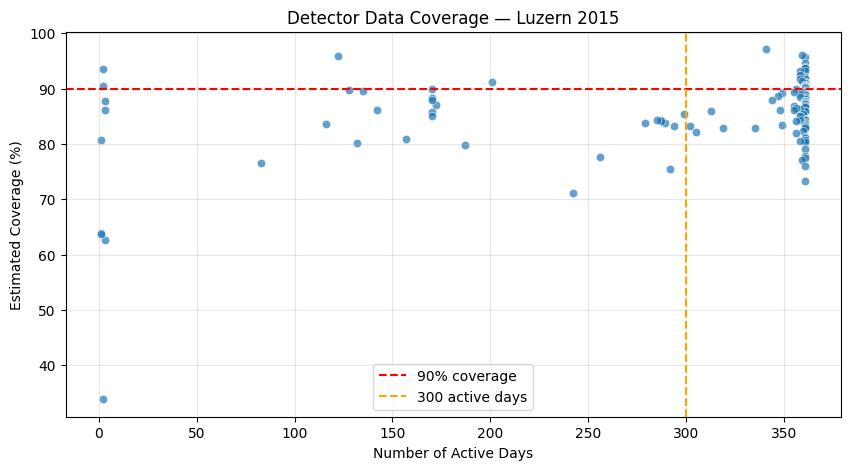

In [13]:
# Detector coverage visualization

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=detector_coverage,
    x="active_days",
    y="coverage_pct",
    alpha=0.7
)

plt.axhline(90, color="red", linestyle="--",
            label="90% coverage")

plt.axvline(300, color="orange", linestyle="--",
            label="300 active days")

plt.title("Detector Data Coverage — Luzern 2015")
plt.xlabel("Number of Active Days")
plt.ylabel("Estimated Coverage (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Večina detektorjev ima meritve za skoraj celotno leto, vendar se ocenjena pokritost posameznih časovnih intervalov med njimi razlikuje. Za nadaljnjo analizo povezav med prometom in zunanjimi dejavniki so primernejši detektorji z visoko časovno pokritostjo in zadostnim številom meritev.

Za zagotavljanje skladnosti s postopkom priprave podatkov za napovedovanje izbor detektorjev temelji na merilih, določenih v zvezku `04_forecasting_preparation.ipynb`.

Za določanje zanesljivosti detektorjev se uporabljajo samo meritve iz učnega obdobja.

In [14]:
TRAIN_END = pd.Timestamp("2015-09-13")

detector_quality = con.execute("""
    WITH daily_quality AS (
        SELECT
            detid,
            day,
            COUNT(DISTINCT interval) AS valid_intervals
        FROM read_parquet(?)
        WHERE day < ?
          AND error IS NULL
          AND flow IS NOT NULL
          AND occ BETWEEN 0 AND 1
          AND flow BETWEEN 0 AND 99998
          AND interval BETWEEN 0 AND 86400
          AND interval % 180 = 0
        GROUP BY detid, day
    )
    SELECT
        detid,
        COUNT(*) FILTER (
            WHERE valid_intervals >= 400
        ) AS reliable_days,
        SUM(valid_intervals) AS valid_observations
    FROM daily_quality
    GROUP BY detid
    HAVING COUNT(*) FILTER (
        WHERE valid_intervals >= 400
    ) >= 175
    ORDER BY reliable_days DESC, valid_observations DESC
""", [str(TRAFFIC_PATH), TRAIN_END.date()]).df()

selected_detectors = detector_quality["detid"].tolist()

print("Selected detectors:", len(selected_detectors))
display(detector_quality.head(10))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Selected detectors: 79


,detid,reliable_days,valid_observations
0,ig11FD103_D3,251,115691.0
1,ig11FD109_D28,251,114427.0
2,ig11FD116_D35,251,113462.0
3,ig11FD202_D33,251,112752.0
4,ig11FD106_D10,251,112698.0
5,ig11FD202_D2,251,111893.0
6,ig11FD104_D5,251,111208.0
7,ig11FD202_D35,251,110867.0
8,ig11FD116_D25,251,110532.0
9,ig11FD203_D11,251,110224.0


Na podlagi meritev iz učnega obdobja smo izbrali 79 detektorjev, ki izpolnjujejo kriterije zanesljivosti. Izbor je usklajen s postopkom priprave podatkov za napovedovanje prometnega toka.

V tem razdelku pripravimo prometne, vremenske in koledarske podatke za skupno analizo.

Prometne meritve so zabeležene v 3-minutnih intervalih, vremenski podatki v urnih intervalih, koledarski podatki pa v dnevnih intervalih.

Pred združevanjem podatkov preverimo strukturo časovnih oznak, da preprečimo nepravilno časovno usklajevanje.

In [15]:
interval_check = con.execute("""
    SELECT
        MIN(interval) AS min_interval,
        MAX(interval) AS max_interval,
        COUNT(DISTINCT interval) AS unique_intervals,
        COUNT(*) FILTER (WHERE interval = 0) AS interval_zero,
        COUNT(*) FILTER (WHERE interval = 86400) AS interval_86400,
        COUNT(*) FILTER (
            WHERE interval % 180 != 0
        ) AS invalid_intervals
    FROM read_parquet(?)
    WHERE error IS NULL
""", [str(TRAFFIC_PATH)]).df()

display(interval_check)

,min_interval,max_interval,unique_intervals,interval_zero,interval_86400,invalid_intervals
0,180,86400,480,0,31215,0


 Prometne meritve uporabljajo 480 različnih časovnih intervalov s korakom 180 sekund, od 00:03 do 24:00. Vsi preverjeni intervali so pravilno razporejeni, pri nadaljnjem združevanju podatkov pa je treba posebej upoštevati oznako 24:00.

In [16]:
timestamp_sample = con.execute("""
    SELECT
        day,
        interval,
        CAST(day AS TIMESTAMP)
            + interval * INTERVAL '1 second' AS timestamp_end,
        CAST(day AS TIMESTAMP)
            + (interval - 180) * INTERVAL '1 second' AS timestamp_start,
        detid,
        flow
    FROM read_parquet(?)
    WHERE error IS NULL
      AND interval IN (180, 360, 3600, 86400)
    ORDER BY day, interval
    LIMIT 12
""", [str(TRAFFIC_PATH)]).df()

display(timestamp_sample)

,day,interval,timestamp_end,timestamp_start,detid,flow
0,2015-01-01,180,2015-01-01 00:03:00,2015-01-01,ig11FD211_D2,120
1,2015-01-01,180,2015-01-01 00:03:00,2015-01-01,ig11FD104_D15,200
2,2015-01-01,180,2015-01-01 00:03:00,2015-01-01,ig11FD202_D4,80
3,2015-01-01,180,2015-01-01 00:03:00,2015-01-01,ig11FD115_D44,100
4,2015-01-01,180,2015-01-01 00:03:00,2015-01-01,ig11FD115_D17,140
5,2015-01-01,180,2015-01-01 00:03:00,2015-01-01,ig11FD107_D4,140
6,2015-01-01,180,2015-01-01 00:03:00,2015-01-01,ig11FD106_D25,40
7,2015-01-01,180,2015-01-01 00:03:00,2015-01-01,ig11FD110_D4,60
8,2015-01-01,180,2015-01-01 00:03:00,2015-01-01,ig11FD208_D2,60
9,2015-01-01,180,2015-01-01 00:03:00,2015-01-01,ig11FD115_D13,140


 Na podlagi dnevnega datuma in 180-sekundnih intervalov smo rekonstruirali začetne in končne časovne oznake prometnih meritev. Pri tem interval 86400 preide v polnoč naslednjega dne; pred združevanjem z vremenskimi podatki je treba potrditi še pomen časovnih oznak.

In [17]:
weather["time_local"] = pd.to_datetime(weather["time_local"])

weather_time_check = pd.DataFrame({
    "total_records": [len(weather)],
    "unique_timestamps": [weather["time_local"].nunique()],
    "first_timestamp": [weather["time_local"].min()],
    "last_timestamp": [weather["time_local"].max()],
    "duplicate_timestamps": [
        weather["time_local"].duplicated().sum()
    ]
})

display(weather_time_check)

weather_sorted = weather.sort_values("time_local")

hourly_differences = (
    weather_sorted["time_local"].diff().value_counts()
)

print("Time differences between consecutive records:")
display(hourly_differences)

,total_records,unique_timestamps,first_timestamp,last_timestamp,duplicate_timestamps
0,8760,8760,2015-01-01,2015-12-31 23:00:00,0


Time differences between consecutive records:


,count
time_local,
0 days 01:00:00,8759


Vremenski podatki vsebujejo 8.760 enoličnih urnih zapisov za leto 2015, brez manjkajočih ali podvojenih časovnih oznak. Pred združevanjem s prometnimi meritvami je treba dodatno preveriti usklajenost časovnih pasov in prehode med poletnim ter zimskim časom.

In [18]:
dst_check = weather[
    (
        (weather["time_local"] >= "2015-03-29 00:00")
        & (weather["time_local"] <= "2015-03-29 05:00")
    )
    |
    (
        (weather["time_local"] >= "2015-10-25 00:00")
        & (weather["time_local"] <= "2015-10-25 05:00")
    )
][["time_local", "temperature_2m_c", "source_timezone"]]

display(dst_check)

,time_local,temperature_2m_c,source_timezone
2088,2015-03-29 00:00:00,6.3,Europe/Berlin
2089,2015-03-29 01:00:00,6.6,Europe/Berlin
2090,2015-03-29 02:00:00,7.2,Europe/Berlin
2091,2015-03-29 03:00:00,7.3,Europe/Berlin
2092,2015-03-29 04:00:00,6.9,Europe/Berlin
2093,2015-03-29 05:00:00,6.6,Europe/Berlin
7128,2015-10-25 00:00:00,11.4,Europe/Berlin
7129,2015-10-25 01:00:00,11.8,Europe/Berlin
7130,2015-10-25 02:00:00,12.4,Europe/Berlin
7131,2015-10-25 03:00:00,14.1,Europe/Berlin


Vremenski podatki vsebujejo neprekinjeno urno časovno zaporedje tudi ob prehodih med poletnim in zimskim časom, zato časovne oznake ne odražajo dejanskih lokalnih premikov ure. Pred združevanjem s prometnimi meritvami je treba preveriti časovno interpretacijo podatkov in preprečiti napačno časovno ujemanje.

In [19]:
weather_dst = weather[
    weather["time_local"].dt.date.isin([
        pd.Timestamp("2015-03-28").date(),
        pd.Timestamp("2015-03-29").date(),
        pd.Timestamp("2015-03-30").date(),
        pd.Timestamp("2015-10-24").date(),
        pd.Timestamp("2015-10-25").date(),
        pd.Timestamp("2015-10-26").date()
    ])
].copy()

daily_weather_counts = (
    weather_dst.groupby(weather_dst["time_local"].dt.date)
    .size()
    .reset_index(name="hourly_records")
)

daily_weather_counts.columns = ["date", "hourly_records"]

display(daily_weather_counts)

,date,hourly_records
0,2015-03-28,24
1,2015-03-29,24
2,2015-03-30,24
3,2015-10-24,24
4,2015-10-25,24
5,2015-10-26,24


Vremenski podatki vsebujejo po 24 urnih zapisov tudi na dneva prehoda med poletnim in zimskim časom. Zaradi negotovosti pri časovni uskladitvi bomo začetno analizo povezav s prometom izvedli na dnevni ravni.

V tem razdelku raziskujemo povezavo med dnevnim prometnim tokom in vremenskimi razmerami, vključno s padavinami in temperaturo.

Prometne meritve združimo na dnevni ravni, da omogočimo primerjavo z dnevnimi povzetki vremenskih podatkov.

In [20]:
weather_daily = (
    weather.assign(date=weather["time_local"].dt.normalize())
    .groupby("date", as_index=False)
    .agg(
        avg_temperature_c=("temperature_2m_c", "mean"),
        total_precipitation_mm=("precipitation_mm", "sum"),
        avg_humidity_pct=("relative_humidity_2m_pct", "mean"),
        avg_wind_kmh=("wind_speed_10m_kmh", "mean")
    )
)

print("Daily weather records:", len(weather_daily))
display(weather_daily.head())

Daily weather records: 365


,date,avg_temperature_c,total_precipitation_mm,avg_humidity_pct,avg_wind_kmh
0,2015-01-01,-0.608333,0.0,93.500000,2.000000
1,2015-01-02,4.041667,2.4,74.708333,4.445833
2,2015-01-03,4.891667,10.5,88.666667,5.295833
3,2015-01-04,3.654167,19.8,93.208333,6.137500
4,2015-01-05,2.512500,0.0,86.416667,3.575000


Urne vremenske podatke smo združili v 365 dnevnih zapisov, ki vsebujejo povprečno temperaturo, skupno količino padavin, povprečno relativno vlažnost in hitrost vetra. Tako pripravljeni podatki omogočajo primerjavo vremenskih razmer z dnevnimi prometnimi meritvami.

In [21]:
con.register(
    "selected_detector_ids",
    detector_quality[["detid"]]
)

traffic_daily = con.execute("""
    SELECT
        CAST(t.day AS DATE) AS date,
        t.detid,
        AVG(t.flow) AS avg_flow,
        AVG(t.occ) AS avg_occupancy,
        COUNT(DISTINCT t.interval) AS observations
    FROM read_parquet(?) AS t
    INNER JOIN selected_detector_ids AS s
        ON t.detid = s.detid
    WHERE t.error IS NULL
      AND t.flow BETWEEN 0 AND 99998
      AND t.occ BETWEEN 0 AND 1
      AND t.interval BETWEEN 180 AND 86400
      AND t.interval % 180 = 0
    GROUP BY t.day, t.detid
    ORDER BY date, t.detid
""", [str(TRAFFIC_PATH)]).df()

print("Daily traffic records:", len(traffic_daily))
print("Detectors:", traffic_daily["detid"].nunique())
print("Days:", traffic_daily["date"].nunique())

display(traffic_daily.head())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Daily traffic records: 28271
Detectors: 79
Days: 361


,date,detid,avg_flow,avg_occupancy,observations
0,2015-01-01,ig11FD100_D3,202.926829,0.055098,410
1,2015-01-01,ig11FD100_D31,295.831486,0.048315,451
2,2015-01-01,ig11FD100_D32,262.537313,0.030659,402
3,2015-01-01,ig11FD100_D33,342.955032,0.065203,467
4,2015-01-01,ig11FD100_D34,188.508772,0.049605,456


 Za 79 izbranih detektorjev smo pripravili 28.271 dnevnih zapisov, ki pokrivajo 361 dni leta 2015. Vsak zapis vsebuje povprečni prometni tok, povprečno zasedenost in število razpoložljivih meritev. Pred analizo povezav z vremenskimi dejavniki bomo upoštevali tudi dnevno pokritost meritev.

In [22]:
MIN_DAILY_OBSERVATIONS = 400

traffic_daily_reliable = traffic_daily[
    traffic_daily["observations"] >= MIN_DAILY_OBSERVATIONS
].copy()

print("Original detector-day records:", len(traffic_daily))
print("Reliable detector-day records:", len(traffic_daily_reliable))
print("Removed records:",
      len(traffic_daily) - len(traffic_daily_reliable))

print("Detectors:", traffic_daily_reliable["detid"].nunique())
print("Days:", traffic_daily_reliable["date"].nunique())

display(traffic_daily_reliable.head())

Original detector-day records: 28271
Reliable detector-day records: 26709
Removed records: 1562
Detectors: 79
Days: 361


,date,detid,avg_flow,avg_occupancy,observations
0,2015-01-01,ig11FD100_D3,202.926829,0.055098,410
1,2015-01-01,ig11FD100_D31,295.831486,0.048315,451
2,2015-01-01,ig11FD100_D32,262.537313,0.030659,402
3,2015-01-01,ig11FD100_D33,342.955032,0.065203,467
4,2015-01-01,ig11FD100_D34,188.508772,0.049605,456


Po uporabi kriterija najmanj 400 razpoložljivih triminutnih intervalov na dan smo ohranili 26.709 od 28.271 dnevnih zapisov (94,5 %). Analiza še vedno vključuje vseh 79 izbranih detektorjev in 361 dni, pri čemer smo izločili dneve z nezadostno pokritostjo meritev.

In [23]:
traffic_daily_reliable["date"] = pd.to_datetime(
    traffic_daily_reliable["date"]
)

weather_daily["date"] = pd.to_datetime(
    weather_daily["date"]
)

calendar["date"] = pd.to_datetime(
    calendar["date"]
)


traffic_weather = traffic_daily_reliable.merge(
    weather_daily,
    on="date",
    how="left",
    validate="many_to_one"
)

traffic_combined = traffic_weather.merge(
    calendar,
    on="date",
    how="left",
    validate="many_to_one"
)

print("Combined records:", len(traffic_combined))
print("Detectors:", traffic_combined["detid"].nunique())
print("Days:", traffic_combined["date"].nunique())

print("\nMissing values:")
display(traffic_combined.isna().sum())

display(traffic_combined.head())

Combined records: 26709
Detectors: 79
Days: 361

Missing values:


,0
date,0
detid,0
avg_flow,0
avg_occupancy,0
observations,0
avg_temperature_c,0
total_precipitation_mm,0
avg_humidity_pct,0
avg_wind_kmh,0
day_of_week,0


,date,detid,avg_flow,avg_occupancy,observations,avg_temperature_c,total_precipitation_mm,avg_humidity_pct,avg_wind_kmh,day_of_week,is_weekend,is_holiday,is_workday
0,2015-01-01,ig11FD100_D3,202.926829,0.055098,410,-0.608333,0.0,93.5,2.0,4,0,1,0
1,2015-01-01,ig11FD100_D31,295.831486,0.048315,451,-0.608333,0.0,93.5,2.0,4,0,1,0
2,2015-01-01,ig11FD100_D32,262.537313,0.030659,402,-0.608333,0.0,93.5,2.0,4,0,1,0
3,2015-01-01,ig11FD100_D33,342.955032,0.065203,467,-0.608333,0.0,93.5,2.0,4,0,1,0
4,2015-01-01,ig11FD100_D34,188.508772,0.049605,456,-0.608333,0.0,93.5,2.0,4,0,1,0


Ta analiza preučuje povezavo med dnevnimi padavinami in povprečnim prometnim tokom na izbranih detektorjih.

Vsak dan je predstavljen samo enkrat, da meritev različnih detektorjev na isti dan ne obravnavamo kot neodvisnih vremenskih opazovanj.

Days available: 361


,date,avg_flow,precipitation_mm,temperature_c,is_weekend,is_holiday,detectors_available
0,2015-01-01,252.080279,0.0,-0.608333,0,1,63
1,2015-01-02,281.913131,2.4,4.041667,0,1,48
2,2015-01-03,305.360808,10.5,4.891667,1,0,70
3,2015-01-04,274.649145,19.8,3.654167,1,0,56
4,2015-01-05,349.989331,0.0,2.512500,0,0,63


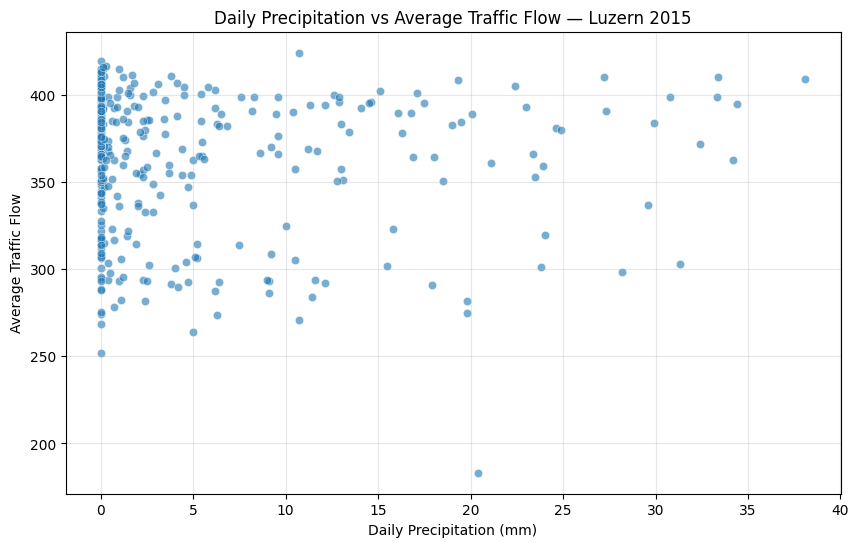

In [24]:
daily_analysis = (
    traffic_combined
    .groupby("date", as_index=False)
    .agg(
        avg_flow=("avg_flow", "mean"),
        precipitation_mm=("total_precipitation_mm", "first"),
        temperature_c=("avg_temperature_c", "first"),
        is_weekend=("is_weekend", "first"),
        is_holiday=("is_holiday", "first"),
        detectors_available=("detid", "nunique")
    )
)

print("Days available:", len(daily_analysis))
display(daily_analysis.head())

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=daily_analysis,
    x="precipitation_mm",
    y="avg_flow",
    alpha=0.6
)

plt.title("Daily Precipitation vs Average Traffic Flow — Luzern 2015")
plt.xlabel("Daily Precipitation (mm)")
plt.ylabel("Average Traffic Flow")
plt.grid(alpha=0.3)
plt.show()

Razsevni diagram ne kaže izrazite linearne povezave med dnevno količino padavin in povprečnim prometnim tokom. Prometni tok se precej razlikuje tudi pri podobnih količinah padavin, zato bomo povezavo dodatno preverili s korelacijsko analizo.

In [25]:
pearson_corr = daily_analysis[
    ["precipitation_mm", "avg_flow"]
].corr(method="pearson").iloc[0, 1]

spearman_corr = daily_analysis[
    ["precipitation_mm", "avg_flow"]
].corr(method="spearman").iloc[0, 1]

print(f"Pearson correlation: {pearson_corr:.4f}")
print(f"Spearman correlation: {spearman_corr:.4f}")

Pearson correlation: -0.0360
Spearman correlation: -0.0846


 Pearsonov korelacijski koeficient (r = -0,0360) in Spearmanov koeficient (ρ = -0,0846) kažeta zelo šibko negativno povezavo med dnevnimi padavinami in povprečnim prometnim tokom. Na ravni celotnega dne zato ni opazne izrazite povezave, vendar se lahko ta razlikuje glede na vrsto dneva in druge dejavnike.

### 4.3 Deževni dnevi v primerjavi s suhimi dnevi

V tej analizi primerjamo povprečni dnevni prometni tok med dnevi s padavinami in dnevi brez padavin.

Cilj je ugotoviti morebitne razlike v prometnih vzorcih pri različnih vremenskih razmerah.

,days,mean_flow,median_flow,std_flow
weather_group,,,,
Dry,150,369.19,377.04,35.35
Rainy,211,359.43,368.19,41.78


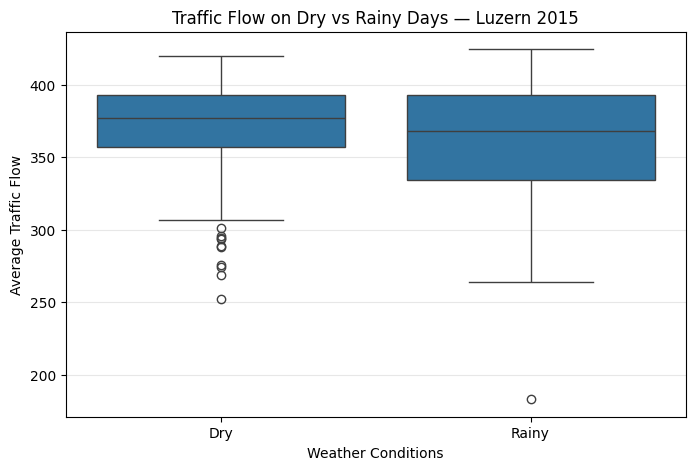

In [26]:
daily_analysis["weather_group"] = np.where(
    daily_analysis["precipitation_mm"] > 0,
    "Rainy",
    "Dry"
)

# Compare traffic flow between groups
rain_comparison = (
    daily_analysis
    .groupby("weather_group")
    .agg(
        days=("date", "count"),
        mean_flow=("avg_flow", "mean"),
        median_flow=("avg_flow", "median"),
        std_flow=("avg_flow", "std")
    )
    .round(2)
)

display(rain_comparison)

# Visual comparison
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=daily_analysis,
    x="weather_group",
    y="avg_flow",
    order=["Dry", "Rainy"]
)

plt.title("Traffic Flow on Dry vs Rainy Days — Luzern 2015")
plt.xlabel("Weather Conditions")
plt.ylabel("Average Traffic Flow")
plt.grid(axis="y", alpha=0.3)
plt.show()

V 150 suhih dneh je povprečni prometni tok znašal 369,19, v 211 dneh s padavinami pa 359,43, kar predstavlja približno 2,64 % nižjo vrednost. V dneh s padavinami je bila večja tudi razpršenost prometnega toka. Ker se porazdelitvi precej prekrivata, razlike ne moremo neposredno pripisati padavinam.

### 4.4 Temperatura in prometni tok

V tej analizi preučujemo povezavo med povprečno dnevno temperaturo in prometnim tokom v Luzernu v letu 2015.

Za oceno moči in smeri povezanosti uporabljamo Pearsonov in Spearmanov korelacijski koeficient.

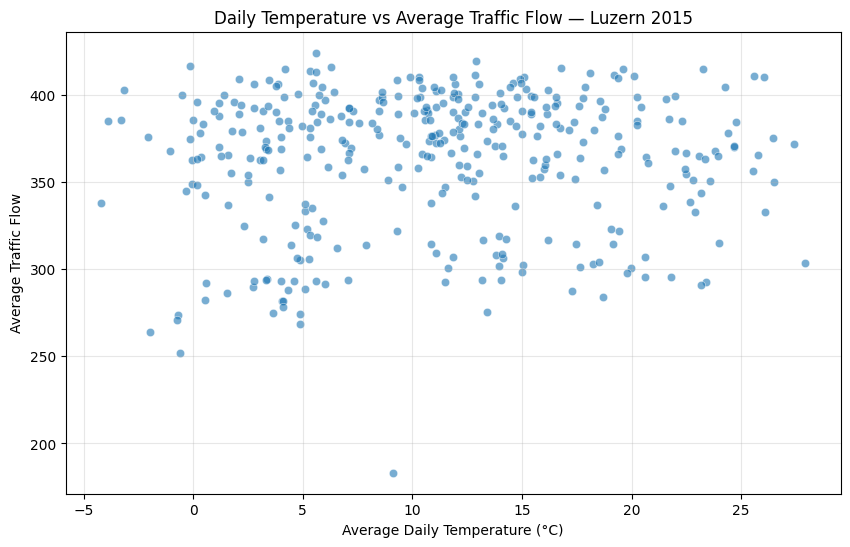

Pearson correlation: 0.0622
Spearman correlation: 0.0406


In [27]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=daily_analysis,
    x="temperature_c",
    y="avg_flow",
    alpha=0.6
)

plt.title("Daily Temperature vs Average Traffic Flow — Luzern 2015")
plt.xlabel("Average Daily Temperature (°C)")
plt.ylabel("Average Traffic Flow")
plt.grid(alpha=0.3)
plt.show()

# Calculate correlations
pearson = daily_analysis[
    ["temperature_c", "avg_flow"]
].corr(method="pearson").iloc[0, 1]

spearman = daily_analysis[
    ["temperature_c", "avg_flow"]
].corr(method="spearman").iloc[0, 1]

print(f"Pearson correlation: {pearson:.4f}")
print(f"Spearman correlation: {spearman:.4f}")

### 4.5 Celovita korelacijska analiza vremenskih dejavnikov

V tej analizi s pomočjo korelacijske matrike preučujemo povezave med prometnim tokom in različnimi vremenskimi dejavniki.

Cilj je prepoznati potencialno pomembne vremenske spremenljivke in raziskati medsebojne povezave med njimi.

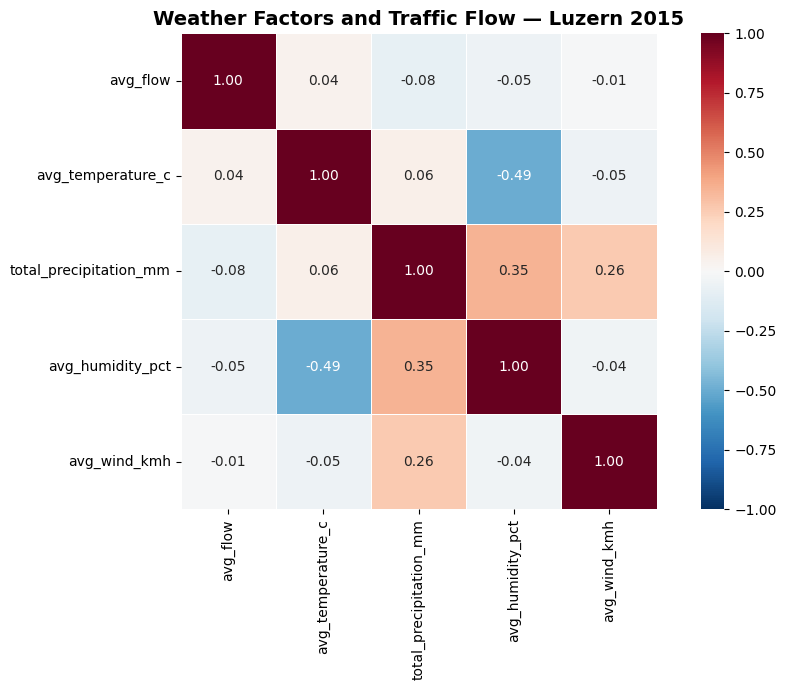

Weather factors ranked by absolute Spearman correlation:


,spearman_correlation
total_precipitation_mm,-0.084634
avg_humidity_pct,-0.051203
avg_temperature_c,0.040574
avg_wind_kmh,-0.008071


In [28]:
weather_features = [
    "avg_temperature_c",
    "total_precipitation_mm",
    "avg_humidity_pct",
    "avg_wind_kmh"
]

# One observation per day
weather_analysis = (
    daily_analysis[["date", "avg_flow"]]
    .merge(
        weather_daily[["date"] + weather_features],
        on="date",
        how="inner",
        validate="one_to_one"
    )
)

# Calculate correlation matrix
correlation_matrix = weather_analysis[
    ["avg_flow"] + weather_features
].corr(method="spearman")

# Visualize correlation matrix
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True
)

plt.title(
    "Weather Factors and Traffic Flow — Luzern 2015",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# Rank weather factors by correlation with traffic flow
weather_ranking = (
    correlation_matrix["avg_flow"]
    .drop("avg_flow")
    .sort_values(key=abs, ascending=False)
)

print("Weather factors ranked by absolute Spearman correlation:")
display(weather_ranking.to_frame("spearman_correlation"))

Korelacijska matrika kaže zelo šibke povezave med posameznimi vremenskimi dejavniki in povprečnim dnevnim prometnim tokom (|ρ| ≤ 0,08). Izrazitejše povezave se pojavljajo med samimi vremenskimi spremenljivkami, predvsem med temperaturo in relativno vlažnostjo (ρ = -0,49).

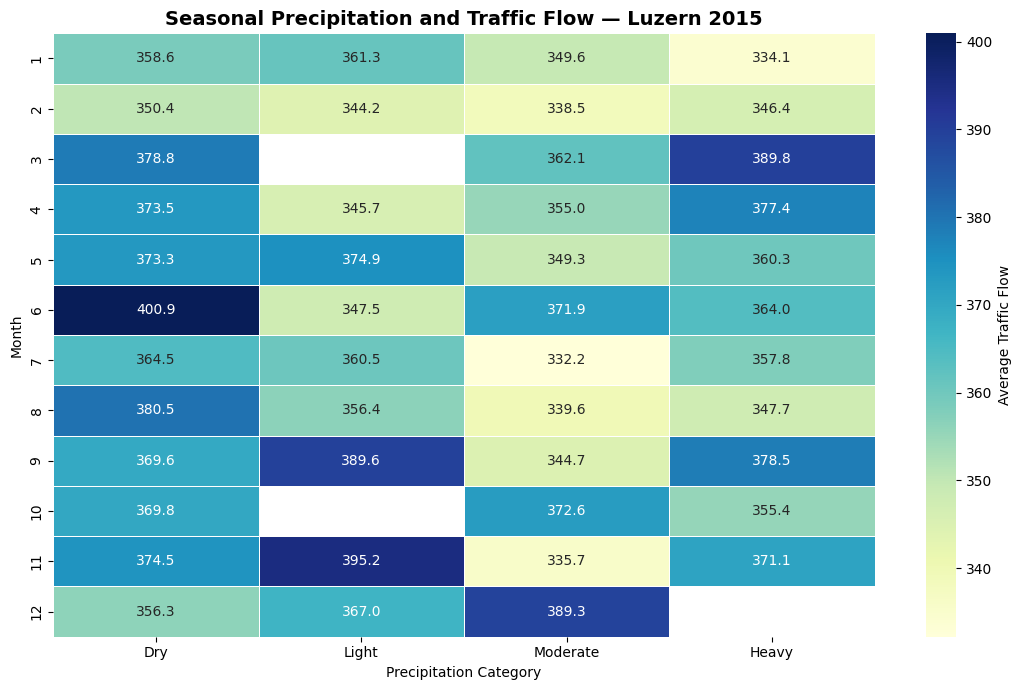

Number of days in each category:


rain_category,Dry,Light,Moderate,Heavy
month,,,,
1,9.0,5.0,10.0,7.0
2,14.0,4.0,7.0,3.0
3,17.0,2.0,6.0,6.0
4,13.0,5.0,6.0,5.0
5,4.0,10.0,7.0,10.0
6,7.0,5.0,9.0,7.0
7,8.0,14.0,6.0,3.0
8,11.0,6.0,4.0,10.0
9,11.0,6.0,7.0,6.0


In [29]:
seasonal_data = daily_analysis.copy()


seasonal_data["month"] = seasonal_data["date"].dt.month

seasonal_data["rain_category"] = pd.cut(
    seasonal_data["precipitation_mm"],
    bins=[-0.001, 0, 2, 10, np.inf],
    labels=["Dry", "Light", "Moderate", "Heavy"]
)


seasonal_heatmap = seasonal_data.pivot_table(
    index="month",
    columns="rain_category",
    values="avg_flow",
    aggfunc="mean",
    observed=True
)


seasonal_counts = seasonal_data.pivot_table(
    index="month",
    columns="rain_category",
    values="avg_flow",
    aggfunc="count",
    observed=True
)


seasonal_heatmap = seasonal_heatmap.where(seasonal_counts >= 3)


plt.figure(figsize=(11, 7))

sns.heatmap(
    seasonal_heatmap,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Average Traffic Flow"}
)

plt.title(
    "Seasonal Precipitation and Traffic Flow — Luzern 2015",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Precipitation Category")
plt.ylabel("Month")
plt.tight_layout()
plt.show()

print("Number of days in each category:")
display(seasonal_counts)

Toplotna karta kaže, da se povezava med količino padavin in povprečnim prometnim tokom razlikuje glede na mesec. Januarja je bil ob močnih padavinah povprečni prometni tok nižji (334,1), medtem ko je bil marca ob enakih padavinskih pogojih precej višji (389,8). Junija je bil največji povprečni prometni tok zabeležen v suhih dneh (400,9), julija pa je bil ob zmernih padavinah nižji (332,2). Rezultati kažejo, da večja količina padavin ni vedno povezana z manjšim prometnim tokom. Na razlike lahko vplivajo tudi sezonski in koledarski dejavniki, kot so vikendi, prazniki in delovni dnevi.

## 5. Analiza vpliva koledarskih dejavnikov

### 5.1 Prometni vzorci glede na vrsto dneva

V tej analizi primerjamo povprečni prometni tok med delovnimi dnevi, konci tedna in prazniki ter preučujemo razlike med posameznimi dnevi v tednu.

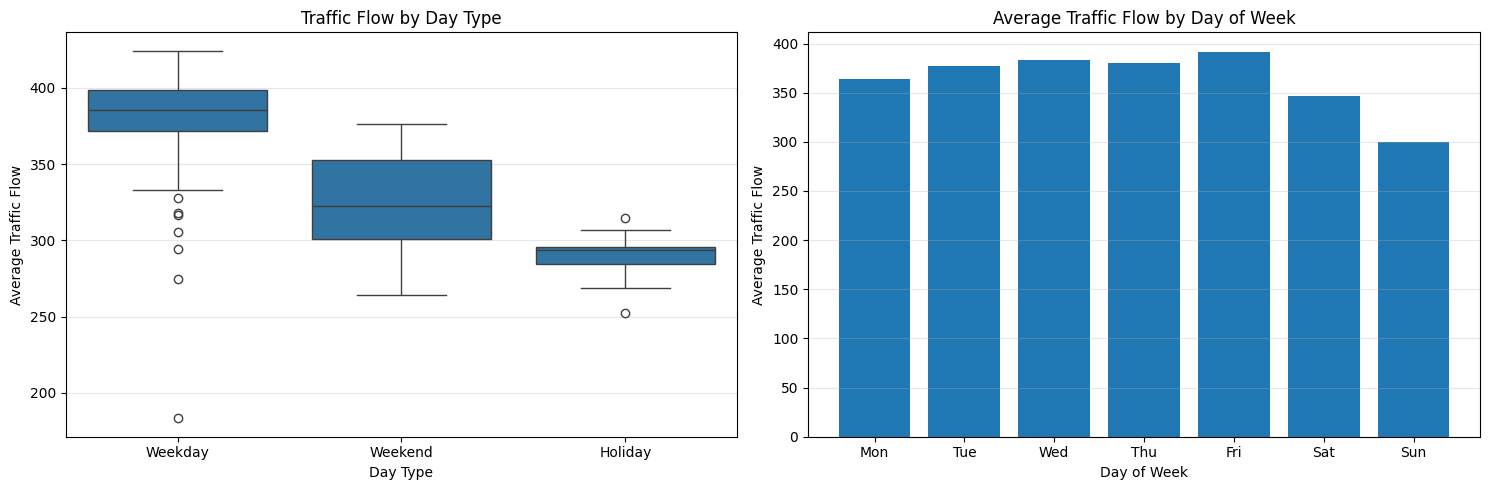

,days,mean_flow,median_flow,std_flow
day_type,,,,
Holiday,13,289.73,293.44,16.01
Weekday,249,382.75,385.74,25.32
Weekend,99,324.72,322.22,29.79


In [31]:
calendar_analysis = daily_analysis.copy()


calendar_analysis["day_type"] = np.select(
    [
        calendar_analysis["is_holiday"] == 1,
        calendar_analysis["is_weekend"] == 1
    ],
    ["Holiday", "Weekend"],
    default="Weekday"
)


calendar_analysis["day_of_week"] = (
    calendar_analysis["date"].dt.dayofweek
)

day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]


fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(
    data=calendar_analysis,
    x="day_type",
    y="avg_flow",
    order=["Weekday", "Weekend", "Holiday"],
    ax=axes[0]
)

axes[0].set_title("Traffic Flow by Day Type")
axes[0].set_xlabel("Day Type")
axes[0].set_ylabel("Average Traffic Flow")
axes[0].grid(axis="y", alpha=0.3)

weekday_flow = (
    calendar_analysis
    .groupby("day_of_week")["avg_flow"]
    .mean()
    .reindex(range(7))
)

axes[1].bar(day_names, weekday_flow.values)
axes[1].set_title("Average Traffic Flow by Day of Week")
axes[1].set_xlabel("Day of Week")
axes[1].set_ylabel("Average Traffic Flow")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


calendar_summary = (
    calendar_analysis
    .groupby("day_type")
    .agg(
        days=("date", "count"),
        mean_flow=("avg_flow", "mean"),
        median_flow=("avg_flow", "median"),
        std_flow=("avg_flow", "std")
    )
    .round(2)
)

display(calendar_summary)

Analiza kaže izrazite razlike v povprečnem prometnem toku glede na vrsto dneva. Največji povprečni prometni tok je bil zabeležen med delovnimi dnevi (382,75), med vikendi je bil nižji za približno 15,2 % (324,72), med prazniki pa za 24,3 % (289,73). Primerjava dni v tednu kaže, da je prometni tok v povprečju največji ob petkih in najmanjši ob nedeljah. Rezultati nakazujejo, da so koledarski dejavniki pomembni kandidati za napovedovanje prometnega toka.

### 5.2 Povezava med vremenskimi in koledarskimi dejavniki

V tej analizi preučujemo, kako so padavinske razmere povezane s prometnim tokom med delovnimi dnevi, konci tedna in prazniki.

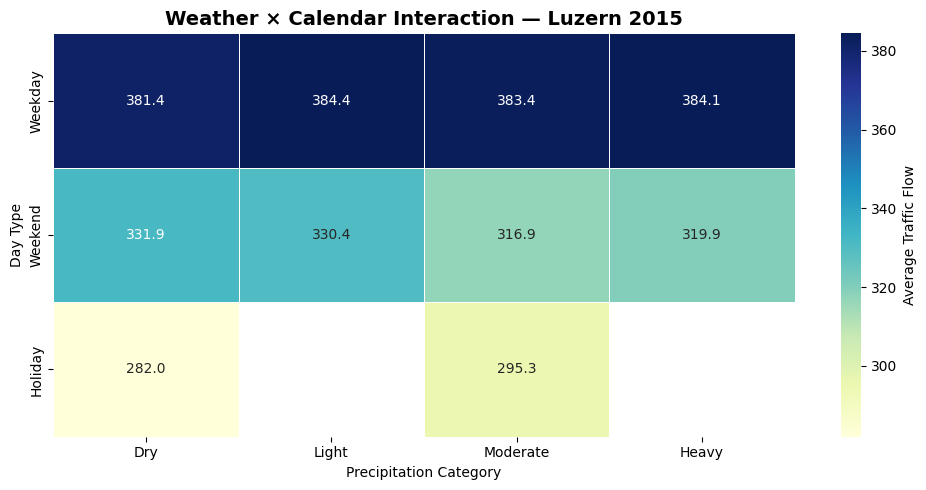

,day_type,rain_category,days,mean_flow
0,Holiday,Dry,5,282.048481
1,Holiday,Light,2,NaN
2,Holiday,Moderate,4,295.339137
3,Holiday,Heavy,2,NaN
4,Weekday,Dry,118,381.424313
5,Weekday,Light,43,384.414786
6,Weekday,Moderate,45,383.399962
7,Weekday,Heavy,43,384.057663
8,Weekend,Dry,27,331.864359
9,Weekend,Light,23,330.376248


In [32]:
interaction_data = calendar_analysis.copy()

interaction_data["rain_category"] = pd.cut(
    interaction_data["precipitation_mm"],
    bins=[-0.001, 0, 2, 10, np.inf],
    labels=["Dry", "Light", "Moderate", "Heavy"]
)


interaction_summary = (
    interaction_data
    .groupby(["day_type", "rain_category"], observed=True)
    .agg(
        days=("avg_flow", "count"),
        mean_flow=("avg_flow", "mean")
    )
    .reset_index()
)


interaction_summary.loc[
    interaction_summary["days"] < 3, "mean_flow"
] = np.nan

interaction_matrix = interaction_summary.pivot(
    index="day_type",
    columns="rain_category",
    values="mean_flow"
)

interaction_matrix = interaction_matrix.reindex(
    ["Weekday", "Weekend", "Holiday"]
)

plt.figure(figsize=(10, 5))

sns.heatmap(
    interaction_matrix,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Average Traffic Flow"}
)

plt.title(
    "Weather × Calendar Interaction — Luzern 2015",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Precipitation Category")
plt.ylabel("Day Type")

plt.tight_layout()
plt.show()

display(interaction_summary)

Analiza kaže, da se povezava med padavinami in prometnim tokom razlikuje glede na vrsto dneva. Med delovnimi dnevi ostaja povprečni prometni tok razmeroma stabilen ne glede na količino padavin (381,4–384,4). Med vikendi je ob zmernih padavinah nižji (316,9) kot v suhih dneh (331,9). Najnižji prometni tok je praviloma zabeležen med prazniki, vendar je zaradi majhnega števila prazničnih dni rezultate treba interpretirati previdno. Ugotovitve nakazujejo, da so koledarski dejavniki močneje povezani s prometnim tokom kot padavine, zato jih je smiselno vključiti v modele za napovedovanje prometa.

## 6. Pokritost detektorjev in zanesljivost rezultatov

V tej analizi preučujemo, ali spremembe v številu razpoložljivih prometnih detektorjev vplivajo na opažene vzorce dnevnega prometnega toka.

Cilj je oceniti zanesljivost primerjav med vremenskimi in koledarskimi dejavniki.

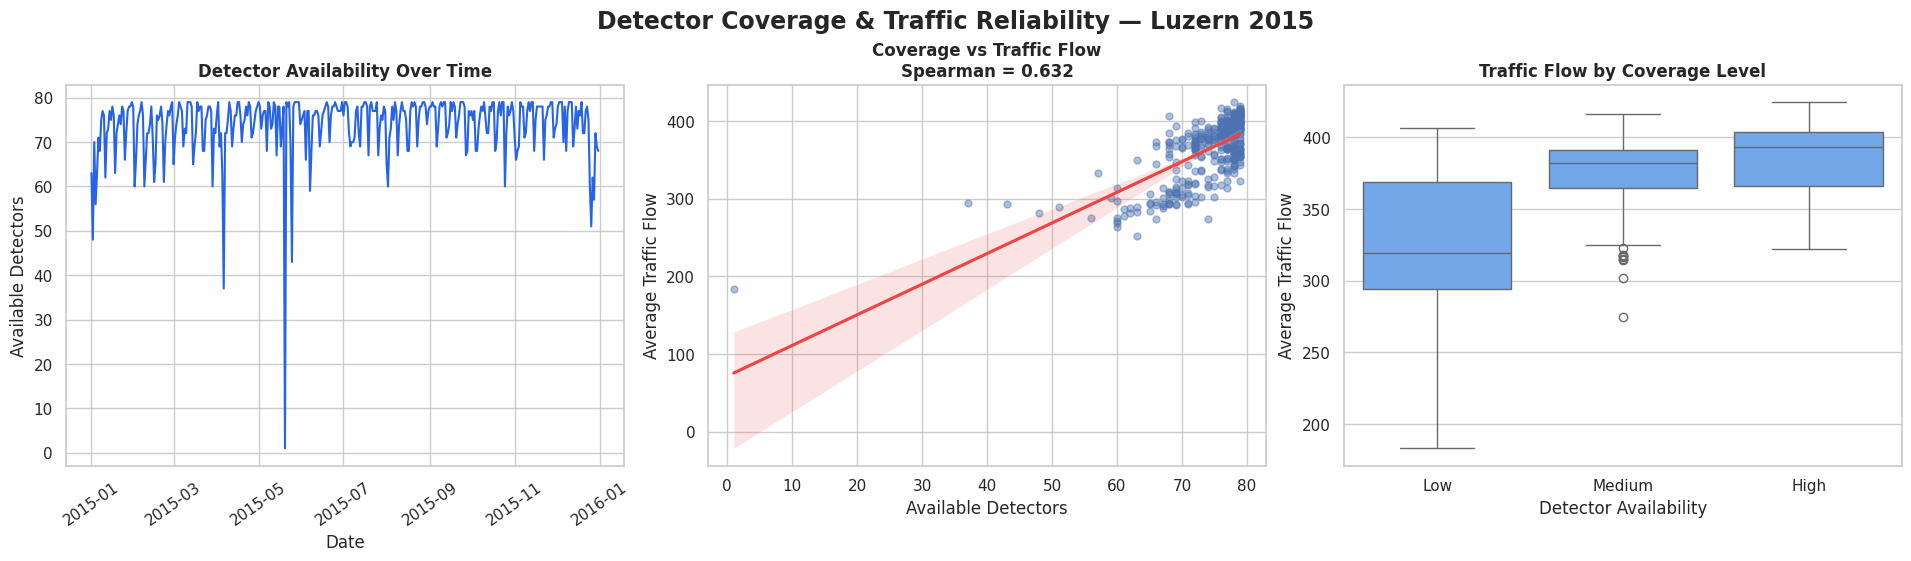

Spearman correlation: 0.6321


,days,avg_detectors,avg_flow,std_flow
coverage_group,,,,
Low,120,67.18,329.26,40.98
Medium,120,76.20,374.57,26.39
High,121,78.55,386.44,22.22


In [33]:
coverage_data = daily_analysis.copy()
coverage_data["date"] = pd.to_datetime(coverage_data["date"])
coverage_data = coverage_data.sort_values("date")


coverage_corr = coverage_data[
    ["detectors_available", "avg_flow"]
].corr(method="spearman").iloc[0, 1]


coverage_data["coverage_group"] = pd.qcut(
    coverage_data["detectors_available"].rank(method="first"),
    q=3,
    labels=["Low", "Medium", "High"]
)

sns.set_theme(style="whitegrid", context="notebook")

fig, axes = plt.subplots(
    1, 3,
    figsize=(19, 5.5),
    constrained_layout=True
)


axes[0].plot(
    coverage_data["date"],
    coverage_data["detectors_available"],
    color="#2563eb",
    linewidth=1.5
)

axes[0].set_title("Detector Availability Over Time", fontweight="bold")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Available Detectors")
axes[0].tick_params(axis="x", rotation=35)

# 2. Relationship between coverage and flow
sns.regplot(
    data=coverage_data,
    x="detectors_available",
    y="avg_flow",
    ax=axes[1],
    scatter_kws={"alpha": 0.45, "s": 25},
    line_kws={"color": "#ef4444"}
)

axes[1].set_title(
    f"Coverage vs Traffic Flow\nSpearman = {coverage_corr:.3f}",
    fontweight="bold"
)
axes[1].set_xlabel("Available Detectors")
axes[1].set_ylabel("Average Traffic Flow")


sns.boxplot(
    data=coverage_data,
    x="coverage_group",
    y="avg_flow",
    order=["Low", "Medium", "High"],
    color="#60a5fa",
    ax=axes[2]
)

axes[2].set_title("Traffic Flow by Coverage Level", fontweight="bold")
axes[2].set_xlabel("Detector Availability")
axes[2].set_ylabel("Average Traffic Flow")

fig.suptitle(
    "Detector Coverage & Traffic Reliability — Luzern 2015",
    fontsize=17,
    fontweight="bold"
)

plt.show()

coverage_summary = (
    coverage_data
    .groupby("coverage_group", observed=True)
    .agg(
        days=("date", "count"),
        avg_detectors=("detectors_available", "mean"),
        avg_flow=("avg_flow", "mean"),
        std_flow=("avg_flow", "std")
    )
    .round(2)
)

print(f"Spearman correlation: {coverage_corr:.4f}")
display(coverage_summary)

 Analiza kaže, da se število razpoložljivih prometnih detektorjev med letom spreminja, kar lahko vpliva na izračun povprečnega prometnega toka. Ugotovljena je zmerno močna pozitivna Spearmanova korelacija (0,632) med številom razpoložljivih detektorjev in povprečnim prometnim tokom. V dneh z nizko razpoložljivostjo detektorjev je povprečni prometni tok znašal 329,26, v dneh z visoko razpoložljivostjo pa 386,44. Rezultati opozarjajo, da je pri interpretaciji vremenskih in koledarskih vplivov treba upoštevati tudi razlike v pokritosti meritev. Za zanesljivejše zaključke je priporočljiva dodatna primerjava na stalnem naboru detektorjev.

### 6.1 Analiza koledarskih vzorcev z enotnim naborom detektorjev

V tej analizi primerjamo prometne vzorce glede na vrsto dneva z uporabo istega nabora detektorjev.

Cilj je zmanjšati morebitno pristranskost rezultatov zaradi sprememb v razpoložljivosti detektorjev.

Eligible detectors: 71


,average_flow
day_type,
Weekday,388.351273
Weekend,324.204296
Holiday,284.173902


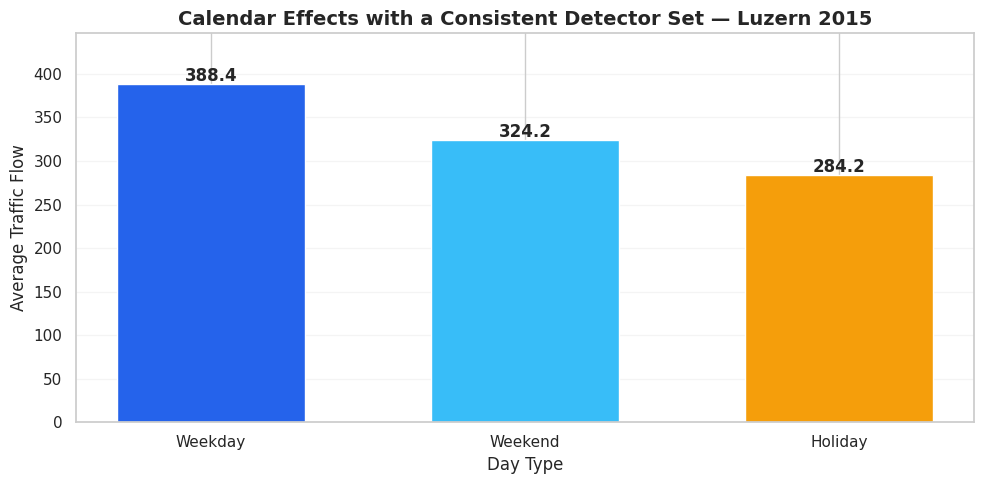

In [34]:
fixed_data = traffic_daily_reliable.copy()
fixed_data["date"] = pd.to_datetime(fixed_data["date"])


fixed_data = fixed_data.merge(
    calendar[["date", "is_weekend", "is_holiday"]].assign(
        date=lambda df: pd.to_datetime(df["date"])
    ),
    on="date",
    how="inner"
)

# Classify days
fixed_data["day_type"] = np.select(
    [
        fixed_data["is_holiday"] == 1,
        fixed_data["is_weekend"] == 1
    ],
    ["Holiday", "Weekend"],
    default="Weekday"
)

# Count observations per detector and day type
detector_counts = (
    fixed_data.groupby(["detid", "day_type"])["date"]
    .nunique()
    .unstack(fill_value=0)
)

# Require sufficient observations in all categories
eligible_detectors = detector_counts[
    (detector_counts["Weekday"] >= 100) &
    (detector_counts["Weekend"] >= 40) &
    (detector_counts["Holiday"] >= 5)
].index

fixed_data = fixed_data[
    fixed_data["detid"].isin(eligible_detectors)
].copy()

print("Eligible detectors:", len(eligible_detectors))

# Mean flow for each detector and day type
detector_means = (
    fixed_data
    .groupby(["detid", "day_type"])["avg_flow"]
    .mean()
    .unstack()
)

# Equal weight for every detector
fixed_summary = detector_means[
    ["Weekday", "Weekend", "Holiday"]
].mean()

display(fixed_summary.to_frame("average_flow"))

# Visual comparison
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    fixed_summary.index,
    fixed_summary.values,
    color=["#2563eb", "#38bdf8", "#f59e0b"],
    width=0.6
)

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 3,
        f"{bar.get_height():.1f}",
        ha="center",
        fontweight="bold"
    )

ax.set_title(
    "Calendar Effects with a Consistent Detector Set — Luzern 2015",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel("Average Traffic Flow")
ax.set_xlabel("Day Type")
ax.set_ylim(0, fixed_summary.max() * 1.15)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

Za preverjanje zanesljivosti rezultatov smo analizo ponovili na enotnem naboru 71 detektorjev. Povprečni prometni tok je bil največji med delovnimi dnevi (388,35), nižji med vikendi (324,20) in najmanjši med prazniki (284,17). V primerjavi z delovnimi dnevi je bil prometni tok med vikendi nižji za približno 16,5 %, med prazniki pa za 26,8 %. Rezultati so podobni prvotni analizi, kar potrjuje, da osnovni koledarski vzorec ostaja prisoten tudi ob uporabi istega nabora detektorjev.

**Končne ugotovitve:** Analiza prometnih podatkov za Luzern v letu 2015 je pokazala, da so koledarski dejavniki izrazito povezani s povprečnim prometnim tokom. Največji promet je bil zabeležen med delovnimi dnevi, najmanjši pa med prazniki. Vremenski dejavniki, predvsem padavine in temperatura, so pokazali šibkejše splošne korelacije, vendar so bile opažene razlike med posameznimi meseci in vrstami dni. Dodatna analiza razpoložljivosti detektorjev je pokazala, da lahko pokritost meritev vpliva na izračunane povprečne vrednosti. Preverjanje na enotnem naboru 71 detektorjev je potrdilo podobne koledarske vzorce. Na podlagi rezultatov je smiselno pri nadaljnjem razvoju napovednih modelov vključiti koledarske in vremenske spremenljivke ter njihovo uporabnost preveriti z vrednotenjem napovedne natančnosti.